# DSE - Data Mining
> Name: Pratyush Pravanjan Pradhan<br>
> Roll no: 251248<br>
> Course: B.Sc. Computer Science hons.<br>
> Project: Breast Cancer (Wisconsin) - preprocessing, classification, clustering and association analysis<br>

## Aim
To apply the data mining techniques covered in the syllabus on the **Breast Cancer Wisconsin (Diagnostic)** dataset and find out which cell measurements separate a **malignant** tumour from a **benign** one.

## Objectives
1. Clean and preprocess the data (aggregation, discretization, binarization, sampling, standardization, normalization).
2. **Classification** - predict malignant / benign using the K-Nearest Neighbours algorithm.
3. **Clustering** - apply K-means (without using the diagnosis) and check if it finds the two groups.
4. **Association analysis** - find rules like `radius_High -> Malignant` using support and confidence.

## Importing the dataset
The dataset is available inside `scikit-learn`, so no download or upload is needed.<br>
It has 569 patients. Each row is a breast lump sample, and the values are measured from the cell nuclei in a microscope image.<br>
For every measurement the dataset has 3 versions (`mean`, `error`, `worst`). **We will only use the `mean` columns**, so we get 10 features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

In [2]:
data = load_breast_cancer(as_frame=True)
full = data.frame

# keeping only the 'mean' columns
mean_cols = [c for c in full.columns if c.startswith('mean ')]
df = full[mean_cols].copy()

# removing the word 'mean ' from the column names to keep them short
df.columns = [c.replace('mean ', '').replace(' ', '_') for c in mean_cols]

# in sklearn 0 = malignant and 1 = benign, so we flip it to make malignant = 1
df['diagnosis'] = (full['target'] == 0).astype(int)
df['diagnosis_name'] = df['diagnosis'].map({1: 'Malignant', 0: 'Benign'})

print(df.shape)
print(df.head())

(569, 12)
   radius  texture  perimeter    area  smoothness  compactness  concavity  \
0   17.99    10.38     122.80  1001.0     0.11840      0.27760     0.3001   
1   20.57    17.77     132.90  1326.0     0.08474      0.07864     0.0869   
2   19.69    21.25     130.00  1203.0     0.10960      0.15990     0.1974   
3   11.42    20.38      77.58   386.1     0.14250      0.28390     0.2414   
4   20.29    14.34     135.10  1297.0     0.10030      0.13280     0.1980   

   concave_points  symmetry  fractal_dimension  diagnosis diagnosis_name  
0         0.14710    0.2419            0.07871          1      Malignant  
1         0.07017    0.1812            0.05667          1      Malignant  
2         0.12790    0.2069            0.05999          1      Malignant  
3         0.10520    0.2597            0.09744          1      Malignant  
4         0.10430    0.1809            0.05883          1      Malignant  


## Dataset Description
| Column | Meaning |
|---|---|
| `radius` | average distance from centre of the nucleus to its edge |
| `texture` | variation in gray-scale values of the pixels |
| `perimeter` | length of the boundary of the nucleus |
| `area` | area of the nucleus |
| `smoothness` | local variation in the radius lengths |
| `compactness` | perimeter² / area - 1 |
| `concavity` | how deep the dents in the boundary are |
| `concave_points` | number of dents in the boundary |
| `symmetry` | symmetry of the nucleus shape |
| `fractal_dimension` | "coastline" complexity of the boundary |
| `diagnosis` | **target** - 1 = Malignant, 0 = Benign |

In [3]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   radius             569 non-null    float64
 1   texture            569 non-null    float64
 2   perimeter          569 non-null    float64
 3   area               569 non-null    float64
 4   smoothness         569 non-null    float64
 5   compactness        569 non-null    float64
 6   concavity          569 non-null    float64
 7   concave_points     569 non-null    float64
 8   symmetry           569 non-null    float64
 9   fractal_dimension  569 non-null    float64
 10  diagnosis          569 non-null    int64  
 11  diagnosis_name     569 non-null    str    
dtypes: float64(10), int64(1), str(1)
memory usage: 53.5 KB
None
           radius     texture   perimeter         area  smoothness  \
count  569.000000  569.000000  569.000000   569.000000  569.000000   
mean    14.127292   19.289649

In [4]:
print(df['diagnosis_name'].value_counts())

diagnosis_name
Benign       357
Malignant    212
Name: count, dtype: int64


## We will now clean and process it

In [5]:
#checking if any column has missing values
print(df.isnull().sum())
print("duplicate rows:", df.duplicated().sum())

radius               0
texture              0
perimeter            0
area                 0
smoothness           0
compactness          0
concavity            0
concave_points       0
symmetry             0
fractal_dimension    0
diagnosis            0
diagnosis_name       0
dtype: int64
duplicate rows: 0


No column has missing values and there are no duplicate rows, so no filling or removing is needed.

## Aggregation.

In [6]:
aggregation = df.groupby('diagnosis_name').agg({
    'radius': 'mean',
    'texture': 'mean',
    'area': 'mean',
    'concavity': 'mean'
})

print(aggregation)

                   radius    texture        area  concavity
diagnosis_name                                             
Benign          12.146524  17.914762  462.790196   0.046058
Malignant       17.462830  21.604906  978.376415   0.160775


In [7]:
aggregation = df.groupby('diagnosis_name').agg({
    'radius': ['mean', 'min', 'max'],
    'area': ['mean', 'median'],
    'concavity': ['mean', 'max']
})

print(aggregation)

                   radius                       area        concavity        
                     mean     min    max        mean median      mean     max
diagnosis_name                                                               
Benign          12.146524   6.981  17.85  462.790196  458.4  0.046058  0.4108
Malignant       17.462830  10.950  28.11  978.376415  932.0  0.160775  0.4268


Malignant tumours have a clearly higher average radius, area and concavity than benign ones.

# Discretization

In [8]:
# custom bins on radius
radius_bins = [0, 12, 15, 40]
radius_labels = ['Small', 'Medium', 'Large']

df['radius_category'] = pd.cut(
    df['radius'],
    bins=radius_bins,
    labels=radius_labels
)

print(df[['radius', 'radius_category']].head())
print(df['radius_category'].value_counts())

   radius radius_category
0   17.99           Large
1   20.57           Large
2   19.69           Large
3   11.42           Small
4   20.29           Large
radius_category
Medium    225
Large     173
Small     171
Name: count, dtype: int64


In [9]:
# equal-frequency bins (each bin gets nearly the same number of rows) using qcut
levels = ['Low', 'Medium', 'High']
for col in ['radius', 'texture', 'smoothness', 'concavity']:
    df[col + '_level'] = pd.qcut(df[col], q=3, labels=levels)

print(df[['radius', 'radius_level', 'concavity', 'concavity_level']].head())
print(df['concavity_level'].value_counts())

   radius radius_level  concavity concavity_level
0   17.99         High     0.3001            High
1   20.57         High     0.0869          Medium
2   19.69         High     0.1974            High
3   11.42          Low     0.2414            High
4   20.29         High     0.1980            High
concavity_level
Low       190
High      190
Medium    189
Name: count, dtype: int64


# Binarization

In [10]:
df['large_radius'] = (df['radius'] >= df['radius'].median()).astype(int)
df['high_concavity'] = (df['concavity'] >= df['concavity'].median()).astype(int)
print(df[['radius', 'concavity', 'large_radius', 'high_concavity']].head())

   radius  concavity  large_radius  high_concavity
0   17.99     0.3001             1               1
1   20.57     0.0869             1               1
2   19.69     0.1974             1               1
3   11.42     0.2414             0               1
4   20.29     0.1980             1               1


In [11]:
# how many malignant / benign in each group
print(pd.crosstab(df['large_radius'], df['diagnosis_name']))

diagnosis_name  Benign  Malignant
large_radius                     
0                  267         17
1                   90        195


# Sampling
selecting a subset of the entire dataset.

In [12]:
sample = df.sample(
    n=100,
    random_state=42
)

print(sample[['radius', 'texture', 'area', 'diagnosis_name']].head(10))
print("\nsample size:", len(sample))

     radius  texture    area diagnosis_name
204   12.47    18.60   481.9         Benign
70    18.94    21.31  1130.0      Malignant
131   15.46    19.48   748.9      Malignant
431   12.40    17.68   467.8         Benign
540   11.54    14.44   402.9         Benign
567   20.60    29.33  1265.0      Malignant
369   22.01    21.90  1482.0      Malignant
29    17.57    15.05   955.1      Malignant
81    13.34    15.86   520.0         Benign
477   13.90    16.62   599.4         Benign

sample size: 100


In [13]:
# checking if the sample has the same ratio of malignant as the full data
print("full data  :", round(df['diagnosis'].mean() * 100, 1), "% malignant")
print("sample     :", round(sample['diagnosis'].mean() * 100, 1), "% malignant")

full data  : 37.3 % malignant
sample     : 37.0 % malignant


## Standardization
$$z = \frac{x - \mu}{\sigma}$$

In [14]:
# selecting the 10 numerical feature columns
features = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
            'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']

df_standardized = df.copy()
df_standardized[features] = (df[features] - df[features].mean()) / df[features].std()
print(df_standardized[features].head())

     radius   texture  perimeter      area  smoothness  compactness  \
0  1.096100 -2.071512   1.268817  0.983510    1.567087     3.280628   
1  1.828212 -0.353322   1.684473  1.907030   -0.826235    -0.486643   
2  1.578499  0.455786   1.565126  1.557513    0.941382     1.052000   
3 -0.768233  0.253509  -0.592166 -0.763792    3.280667     3.399917   
4  1.748758 -1.150804   1.775011  1.824624    0.280125     0.538866   

   concavity  concave_points  symmetry  fractal_dimension  
0   2.650542        2.530249  2.215566           2.253764  
1  -0.023825        0.547662  0.001391          -0.867889  
2   1.362280        2.035440  0.938859          -0.397658  
3   1.914213        1.450431  2.864862           4.906602  
4   1.369806        1.427237 -0.009552          -0.561956  


In [15]:
print(df_standardized[features].mean().round(3))
print(df_standardized[features].std().round(3))

radius              -0.0
texture              0.0
perimeter           -0.0
area                -0.0
smoothness          -0.0
compactness          0.0
concavity            0.0
concave_points      -0.0
symmetry             0.0
fractal_dimension    0.0
dtype: float64
radius               1.0
texture              1.0
perimeter            1.0
area                 1.0
smoothness           1.0
compactness          1.0
concavity            1.0
concave_points       1.0
symmetry             1.0
fractal_dimension    1.0
dtype: float64


## Normalization
$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

In [16]:
df_normalized = df.copy()
df_normalized[features] = (df[features] - df[features].min()) / (df[features].max() - df[features].min())
print(df_normalized[features].head())
print("\nmin:", df_normalized[features].min().min(), " max:", df_normalized[features].max().max())

     radius   texture  perimeter      area  smoothness  compactness  \
0  0.521037  0.022658   0.545989  0.363733    0.593753     0.792037   
1  0.643144  0.272574   0.615783  0.501591    0.289880     0.181768   
2  0.601496  0.390260   0.595743  0.449417    0.514309     0.431017   
3  0.210090  0.360839   0.233501  0.102906    0.811321     0.811361   
4  0.629893  0.156578   0.630986  0.489290    0.430351     0.347893   

   concavity  concave_points  symmetry  fractal_dimension  
0   0.703140        0.731113  0.686364           0.605518  
1   0.203608        0.348757  0.379798           0.141323  
2   0.462512        0.635686  0.509596           0.211247  
3   0.565604        0.522863  0.776263           1.000000  
4   0.463918        0.518390  0.378283           0.186816  

min: 0.0  max: 1.0


`area` is in hundreds/thousands while `smoothness` is around 0.1, so without scaling `area` would dominate any distance calculation. That is why scaling is needed before KNN and K-means.

# Classification - K-Nearest Neighbours (KNN)
**Idea:** to classify a new patient, find the `k` closest patients in the training data (Euclidean distance) and take the majority vote of their diagnosis.

$$d(x,y) = \sqrt{\sum_j (x_j-y_j)^2}$$

**Steps:** split into train/test &rarr; normalize &rarr; apply KNN &rarr; find accuracy.

In [17]:
np.random.seed(42)

X = df[features].values
y = df['diagnosis'].values

# shuffling and splitting 80% train, 20% test
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
train_idx, test_idx = idx[:split], idx[split:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]
print("train:", X_train.shape, " test:", X_test.shape)

train: (455, 10)  test: (114, 10)


In [18]:
# normalizing using the min and max of the TRAINING data only
mn = X_train.min(axis=0)
mx = X_train.max(axis=0)
X_train_n = (X_train - mn) / (mx - mn)
X_test_n = (X_test - mn) / (mx - mn)

In [19]:
def knn_predict(X_train, y_train, X_test, k):
    predictions = []
    for point in X_test:
        dist = np.sqrt(np.sum((X_train - point) ** 2, axis=1))   # distance to every training point
        nearest = np.argsort(dist)[:k]                           # indices of k closest
        votes = np.bincount(y_train[nearest])                    # count 0s and 1s
        predictions.append(np.argmax(votes))                     # majority vote
    return np.array(predictions)

In [20]:
k = 5
y_pred = knn_predict(X_train_n, y_train, X_test_n, k)

accuracy = np.mean(y_pred == y_test)
print(f"Accuracy for k={k}: {accuracy:.4f}")

Accuracy for k=5: 0.9474


In [21]:
# confusion matrix
TP = np.sum((y_pred == 1) & (y_test == 1))
TN = np.sum((y_pred == 0) & (y_test == 0))
FP = np.sum((y_pred == 1) & (y_test == 0))
FN = np.sum((y_pred == 0) & (y_test == 1))

print(pd.DataFrame(
    [[TN, FP], [FN, TP]],
    index=['Actual Benign', 'Actual Malignant'],
    columns=['Predicted Benign', 'Predicted Malignant']
))

precision = TP / (TP + FP)
recall = TP / (TP + FN)
print(f"\nPrecision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")

                  Predicted Benign  Predicted Malignant
Actual Benign                   65                    2
Actual Malignant                 4                   43

Precision: 0.9556
Recall   : 0.9149


$$Precision = \frac{TP}{TP+FP} \qquad Recall = \frac{TP}{TP+FN}$$
**Recall** is the important one here, because a malignant tumour wrongly predicted as benign (FN) is the most dangerous mistake.

In [22]:
# trying different values of k
results = []
for k in [1, 3, 5, 7, 9, 11]:
    pred = knn_predict(X_train_n, y_train, X_test_n, k)
    results.append({"k": k, "accuracy": np.mean(pred == y_test)})
print(pd.DataFrame(results).to_string(index=False))

 k  accuracy
 1  0.929825
 3  0.947368
 5  0.947368
 7  0.938596
 9  0.947368
11  0.964912


In [23]:
# effect of normalization: same KNN on raw (unscaled) data
pred_raw = knn_predict(X_train, y_train, X_test, 5)
print("Accuracy WITHOUT normalization:", round(np.mean(pred_raw == y_test), 4))
print("Accuracy WITH normalization   :", round(np.mean(y_pred == y_test), 4))

Accuracy WITHOUT normalization: 0.8596
Accuracy WITH normalization   : 0.9474


# K-means Clustering
Clustering is **unsupervised** - we will not give the diagnosis to the algorithm. Then we compare the clusters with the real diagnosis.

The Euclidean distance between a data point `x` and centroid `c` is:

$$
d(x,c) = \sqrt{\sum_j (x_j-c_j)^2}
$$

The MSE used here is the mean of the squared distances of each point from its assigned centroid:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n} d(x_i,c_i)^2
$$

In [24]:
def kmeans(data, k, max_iter=100):
  data=np.asarray(data,dtype=float)
  idx = np.random.choice(len(data), k, replace=False)
  centroids=data[idx].copy()
  mse_history=[]

  for i in range(max_iter):
    dist = np.linalg.norm(
      data[:, np.newaxis, :] - centroids,
      axis=2
    )
    labels=np.argmin(dist,axis=1)
    new_centroids=np.array([np.mean(data[labels==j],axis=0) if np.any(labels==j) else centroids[j] for j in range(k)])

    point_dist=np.min(dist,axis=1)
    mse=np.mean(point_dist**2)
    mse_history.append(mse)

    if np.all(centroids==new_centroids):
      break
    centroids=new_centroids
  return centroids,mse_history,labels

In [25]:
# using the standardized features (all 10 columns, diagnosis is NOT used)
cluster_data = df_standardized[features].values
print(cluster_data.shape)

(569, 10)


In [26]:
np.random.seed(1)
k = 2

centroids, mse_history, labels = kmeans(cluster_data, k=k, max_iter=100)

print("Number of iterations:", len(mse_history))
print("Final MSE:", mse_history[-1])
print("Cluster sizes:", np.bincount(labels))

Number of iterations: 7
Final MSE: 6.107854524329356
Cluster sizes: [169 400]


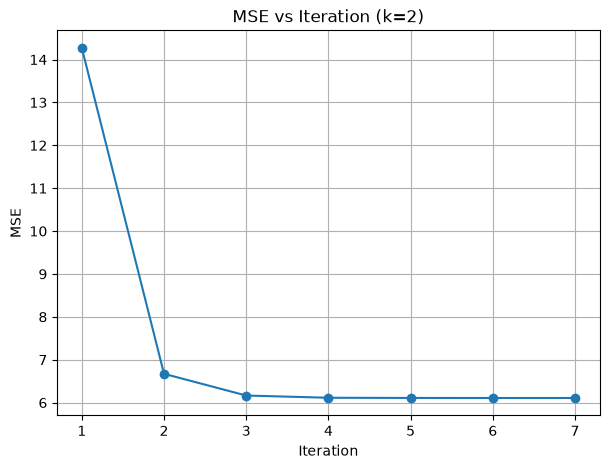

MSE after each iteration:
Iteration 1: 14.2690
Iteration 2: 6.6717
Iteration 3: 6.1652
Iteration 4: 6.1133
Iteration 5: 6.1091
Iteration 6: 6.1080
Iteration 7: 6.1079


In [27]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(mse_history) + 1),
    mse_history,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("MSE vs Iteration (k=2)")
plt.xticks(range(1, len(mse_history) + 1))
plt.grid()
plt.show()

print("MSE after each iteration:")
for i, mse in enumerate(mse_history, start=1):
    print(f"Iteration {i}: {mse:.4f}")

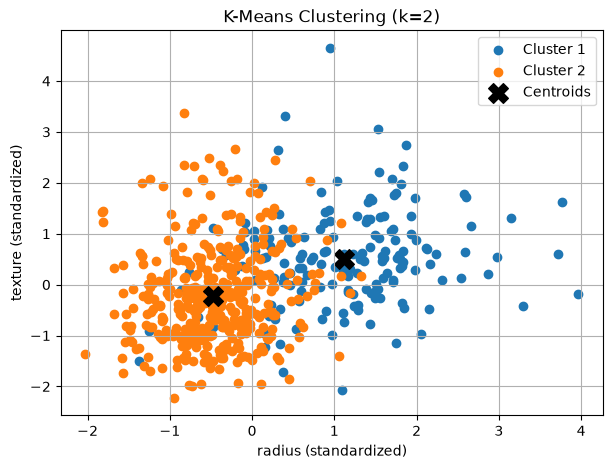

In [28]:
# Visualize the clusters using two features (radius and texture, standardized)
plt.figure(figsize=(7, 5))

for cluster in range(k):
    pts = cluster_data[labels == cluster]
    plt.scatter(pts[:, 0], pts[:, 1], label=f"Cluster {cluster + 1}")

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Centroids"
)

plt.xlabel("radius (standardized)")
plt.ylabel("texture (standardized)")
plt.title("K-Means Clustering (k=2)")
plt.legend()
plt.grid()
plt.show()

### Comparing the clusters with the real diagnosis

In [29]:
print(pd.crosstab(labels, df['diagnosis_name'], rownames=['cluster']))

# each cluster is named after the majority diagnosis inside it
table = pd.crosstab(labels, df['diagnosis'])
correct = table.max(axis=1).sum()
print("\nCluster purity:", round(correct / len(df) * 100, 2), "%")

diagnosis_name  Benign  Malignant
cluster                          
0                    6        163
1                  351         49

Cluster purity: 90.33 %


Even though K-means never saw the diagnosis, the two clusters match the real malignant / benign groups quite well.

In [30]:
# comparing different values of k
results = []
for k in [2, 3, 4, 5]:
    np.random.seed(1)
    c_k, mse_k, labels_k = kmeans(cluster_data, k=k, max_iter=100)
    results.append({
        "k": k,
        "iterations": len(mse_k),
        "final_MSE": mse_k[-1]
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 k  iterations  final_MSE
 2           7   6.107855
 3          17   5.000129
 4          12   4.376044
 5          22   3.855014


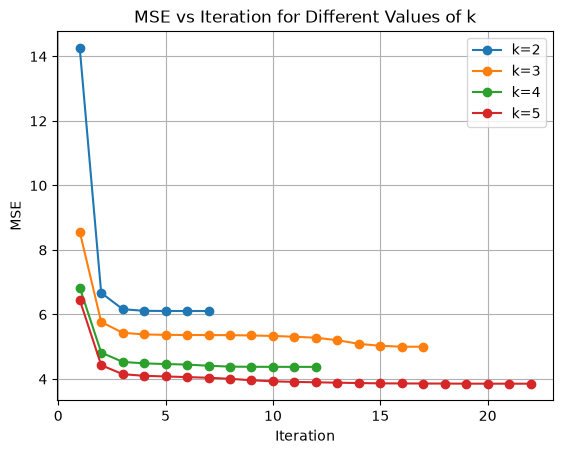

In [31]:
for k in [2, 3, 4, 5]:
    np.random.seed(1)
    c_k, mse_k, labels_k = kmeans(cluster_data, k=k, max_iter=100)
    plt.plot(range(1, len(mse_k) + 1), mse_k, marker="o", label=f"k={k}")

plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("MSE vs Iteration for Different Values of k")
plt.legend()
plt.grid()
plt.show()

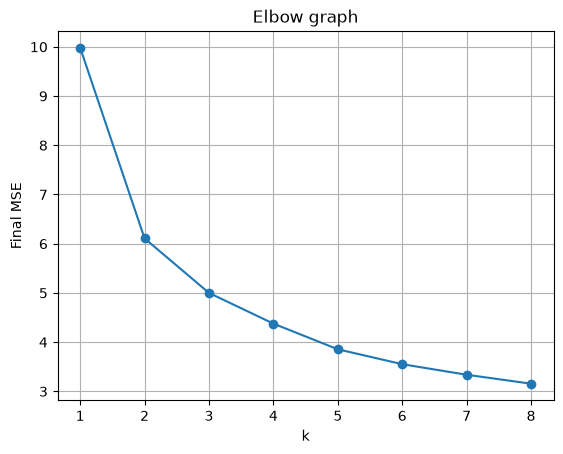

In [32]:
# elbow graph: final MSE for k = 1 to 8
final_mse = []
for k in range(1, 9):
    np.random.seed(1)
    _, mse_k, _ = kmeans(cluster_data, k=k, max_iter=100)
    final_mse.append(mse_k[-1])

plt.plot(range(1, 9), final_mse, marker="o")
plt.xlabel("k")
plt.ylabel("Final MSE")
plt.title("Elbow graph")
plt.grid()
plt.show()

# Association Analysis
Association rules need **transactions made of items**, so we use the discretized columns. Every patient becomes one transaction, for example:

`{radius_High, texture_High, concavity_High, Malignant}`

## Making the transactions

In [33]:
transactions = []
for i in range(len(df)):
    t = {
        'radius_' + str(df['radius_level'][i]),
        'texture_' + str(df['texture_level'][i]),
        'smoothness_' + str(df['smoothness_level'][i]),
        'concavity_' + str(df['concavity_level'][i]),
        df['diagnosis_name'][i]
    }
    transactions.append(t)

print("Total transactions:", len(transactions))
for t in transactions[:5]:
    print(sorted(t))

Total transactions: 569
['Malignant', 'concavity_High', 'radius_High', 'smoothness_High', 'texture_Low']
['Malignant', 'concavity_Medium', 'radius_High', 'smoothness_Low', 'texture_Medium']
['Malignant', 'concavity_High', 'radius_High', 'smoothness_High', 'texture_High']
['Malignant', 'concavity_High', 'radius_Low', 'smoothness_High', 'texture_Medium']
['Malignant', 'concavity_High', 'radius_High', 'smoothness_Medium', 'texture_Low']


## Support for the items in itemset
$$Support(X)=\frac{\text{Number of transactions containing X}}{\text{Total number of transaction}}$$
We will store it in a dataframe to display it better in a tabular form.

In [34]:
itemsets = [
    {'Malignant'},
    {'Benign'},
    {'radius_High'},
    {'radius_Low'},
    {'concavity_High'},
    {'radius_High', 'concavity_High'},
    {'radius_High', 'Malignant'},
    {'radius_Low', 'Benign'},
    {'radius_High', 'concavity_High', 'Malignant'}
]

In [35]:
total_transac=len(transactions)
support_itemsets=[]
for i in itemsets:
    count = sum(i.issubset(tran) for tran in transactions)
    support = count/total_transac
    support_itemsets.append({
        'items':', '.join(sorted(i)),
        'count':count,
        'support':round(support,4)
    })
print(pd.DataFrame(support_itemsets).to_string())

                                    items  count  support
0                               Malignant    212   0.3726
1                                  Benign    357   0.6274
2                             radius_High    190   0.3339
3                              radius_Low    191   0.3357
4                          concavity_High    190   0.3339
5             concavity_High, radius_High    139   0.2443
6                  Malignant, radius_High    167   0.2935
7                      Benign, radius_Low    185   0.3251
8  Malignant, concavity_High, radius_High    137   0.2408


## Support and Confidence for association rules
We will make two separate function for each. </br>
For a rule $X \rightarrow Y$:
$$
Support(X \rightarrow Y) = Support(X \cup Y)
$$
$$
Confidence(X \rightarrow Y) = \frac{Support(X \cup Y)}{Support(X)}
$$

In [36]:
def support(transaction,X,Y=None):
    if Y is not None:
        return support(transaction,X.union(Y))
    count=sum(X.issubset(j) for j in transaction)
    return count/len(transaction)
def confidence(transaction,X,Y):
    return support(transaction,X,Y)/support(transaction,X)

And again store it in a dataframe to display it

In [37]:
rules = [
    ({'radius_High'}, {'Malignant'}),
    ({'concavity_High'}, {'Malignant'}),
    ({'radius_High', 'concavity_High'}, {'Malignant'}),
    ({'radius_Low'}, {'Benign'}),
    ({'concavity_Low'}, {'Benign'}),
    ({'radius_Low', 'concavity_Low'}, {'Benign'}),
    ({'Malignant'}, {'radius_High'}),
    ({'texture_High'}, {'Malignant'}),
    ({'smoothness_High'}, {'Malignant'})
]

In [38]:
results = []
for X, Y in rules:
    results.append({
        "Antecedent": ", ".join(sorted(X)),
        "Consequent": ", ".join(sorted(Y)),
        "Support": round(support(transactions, X, Y), 4),
        "Confidence": round(confidence(transactions, X, Y), 4)
    })
df_rules = pd.DataFrame(results)
print(df_rules.to_string(index=False))

                 Antecedent  Consequent  Support  Confidence
                radius_High   Malignant   0.2935      0.8789
             concavity_High   Malignant   0.2935      0.8789
concavity_High, radius_High   Malignant   0.2408      0.9856
                 radius_Low      Benign   0.3251      0.9686
              concavity_Low      Benign   0.3234      0.9684
  concavity_Low, radius_Low      Benign   0.1898      0.9908
                  Malignant radius_High   0.2935      0.7877
               texture_High   Malignant   0.2109      0.6349
            smoothness_High   Malignant   0.1898      0.5684


### Strong rules
A rule is considered strong if it has a good **support** and a high **confidence**. Using minimum support = 0.15 and minimum confidence = 0.80:

In [39]:
min_support = 0.15
min_confidence = 0.80

strong = df_rules[(df_rules['Support'] >= min_support) & (df_rules['Confidence'] >= min_confidence)]
print(strong.to_string(index=False))

                 Antecedent Consequent  Support  Confidence
                radius_High  Malignant   0.2935      0.8789
             concavity_High  Malignant   0.2935      0.8789
concavity_High, radius_High  Malignant   0.2408      0.9856
                 radius_Low     Benign   0.3251      0.9686
              concavity_Low     Benign   0.3234      0.9684
  concavity_Low, radius_Low     Benign   0.1898      0.9908


# Conclusion
- The data had no missing values. Preprocessing techniques (aggregation, discretization, binarization, sampling, standardization, normalization) were applied on the 10 `mean` features.
- **KNN** classified malignant / benign tumours with high accuracy, and normalization improved its accuracy because the features were on very different scales.
- **K-means** with k = 2, without using the diagnosis, produced two clusters that match the real diagnosis closely.
- **Association rules** showed that large radius / high concavity cells are strongly associated with *Malignant*, and small radius / low concavity with *Benign*.